# Ottawa WUI Mapper — Interactive Baseline
OSS4008A | Chidubem Udobi

This notebook visualizes Canadian satellite imagery, NDVI, and Canadian forest land cover. **It does not yet detect homes using AI.** Run top-to-bottom in Google Colab.


In [1]:
%pip -q install geemap


In [2]:
import ee
import geemap
from IPython.display import display

EE_PROJECT = "psychic-apex-509318-e5"

# Use a browser authorization flow instead of Colab's
# automatic credential propagation.
ee.Authenticate(auth_mode="notebook", force=True)

ee.Initialize(project=EE_PROJECT)

print("Earth Engine initialized successfully!")



To authorize access needed by Earth Engine, open the following URL in a web browser and follow the instructions. If the web browser does not start automatically, please manually browse the URL below.

    https://code.earthengine.google.com/client-auth?scopes=https%3A//www.googleapis.com/auth/earthengine%20https%3A//www.googleapis.com/auth/cloud-platform%20https%3A//www.googleapis.com/auth/drive%20https%3A//www.googleapis.com/auth/devstorage.full_control&request_id=FzWULw-RGsKzMOqmyzwAf2qU_AEe84-mgi1E_Q_RoXE&tc=q-p7BQvQnNwH07CD_FSfQN9eKvljA0tYBQPpfByIdMs&cc=yfiKIJPKk66BRa7PfySbg_ivjNLI4ZcDy3_D_0BHrh0

The authorization workflow will generate a code, which you should paste in the box below.
Enter verification code: 4/1AUn6Hd_YV6HY_HxIUj5VzIfF6qVAWQG0LXGfdPufXzKLC2bWnwDBdLDTblM

Successfully saved authorization token.
Earth Engine initialized successfully!


In [3]:
# Small pilot area in Kanata, Ottawa
study_area = ee.Geometry.Rectangle([-75.94, 45.29, -75.88, 45.34])
start_date, end_date = '2025-05-01', '2025-10-01'
sentinel = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
    .filterBounds(study_area)
    .filterDate(start_date, end_date)
    .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20)))
scene_count = sentinel.size().getInfo()
print('Sentinel-2 scenes:', scene_count)
if scene_count == 0:
    raise RuntimeError('No Sentinel-2 scenes found; widen date range or cloud threshold')
composite = sentinel.median().clip(study_area)
ndvi = composite.normalizedDifference(['B8', 'B4']).rename('NDVI')


Sentinel-2 scenes: 12


In [4]:
# Select latest available AAFC ACI image overlapping the Ottawa pilot
aci_collection = ee.ImageCollection('AAFC/ACI').filterBounds(study_area).sort('system:time_start', False)
if aci_collection.size().getInfo() == 0:
    raise RuntimeError('No AAFC ACI images returned')
aci = ee.Image(aci_collection.first()).clip(study_area)
print('AAFC image date:', ee.Date(aci.get('system:time_start')).format('YYYY-MM-dd').getInfo())
# AAFC ACI codes for coniferous, broadleaf, and mixedwood forest: 210, 220, 230
# Validate the dataset legend for the returned year before drawing conclusions.
forest = aci.remap([210, 220, 230], [1, 1, 1], 0).selfMask()


AAFC image date: 2025-01-01


In [5]:
m = geemap.Map(center=[45.315, -75.91], zoom=12, basemap='Esri.WorldImagery')
m.addLayer(composite, {'bands': ['B4', 'B3', 'B2'], 'min': 0, 'max': 3000}, 'Sentinel-2 RGB 2025')
m.addLayer(ndvi, {'min': -0.2, 'max': 0.8, 'palette': ['#8c510a', '#f6e8c3', '#a6dba0', '#01665e']}, 'NDVI 2025', False)
m.addLayer(forest, {'palette': ['#16803c']}, 'AAFC forest classes', True)
m.addLayer(ee.Image().paint(study_area, 1, 2), {'palette': ['#ffb000']}, 'Study area')
m.addLayerControl()

# Map is displayed in the final Phase II selection cell below.


In [6]:

import ipywidgets as widgets
from IPython.display import display
from ipywidgets import Layout

# ---- Dashboard title ----
title = widgets.HTML(
    "<h2>Residential Mapping & WUI Explorer</h2>"
    "<p>OSS4008A | Ottawa, Ontario | Progress 2</p>"
)

# ---- Results panel ----
status = widgets.HTML("<b>Status:</b> Dashboard ready.")
location = widgets.HTML("<b>Selected location:</b> Click on the map.")
analysis = widgets.HTML(
    "<b>Available analysis:</b><br>"
    "Sentinel-2 imagery (2025)<br>"
    "NDVI vegetation index<br>"
    "AAFC forest classification<br><br>"
    "<b>Under development:</b><br>"
    "AI building detection<br>"
    "Building-to-forest proximity screening"
)

# ---- Buttons ----
satellite_btn = widgets.Button(
    description="Satellite",
    button_style="info",
    icon="globe"
)
forest_btn = widgets.Button(
    description="Forest Cover",
    button_style="success",
    icon="tree"
)
ndvi_btn = widgets.Button(
    description="NDVI",
    button_style="warning",
    icon="leaf"
)
reset_btn = widgets.Button(
    description="Reset Map",
    icon="refresh"
)

# Find existing map layers by their names
def get_layer(name):
    for layer in m.layers:
        if layer.name == name:
            return layer
    return None

def toggle_layer(name):
    layer = get_layer(name)
    if layer is None:
        status.value = f"<b>Status:</b> Layer not found: {name}"
        return

    layer.visible = not layer.visible
    state = "ON" if layer.visible else "OFF"
    status.value = f"<b>Status:</b> {name} switched {state}"

# Button actions
def on_satellite_clicked(button):
    toggle_layer("Sentinel-2 RGB 2025")

def on_forest_clicked(button):
    toggle_layer("AAFC forest classes")

def on_ndvi_clicked(button):
    toggle_layer("NDVI 2025")

def on_reset_clicked(button):
    m.center = (45.315, -75.91)
    m.zoom = 12

    defaults = {
        "Sentinel-2 RGB 2025": True,
        "AAFC forest classes": True,
        "NDVI 2025": False,
        "Study area": True
    }

    for name, visible in defaults.items():
        layer = get_layer(name)
        if layer is not None:
            layer.visible = visible

    location.value = "<b>Selected location:</b> Click on the map."
    status.value = "<b>Status:</b> Map reset to Ottawa."

satellite_btn.on_click(on_satellite_clicked)
forest_btn.on_click(on_forest_clicked)
ndvi_btn.on_click(on_ndvi_clicked)
reset_btn.on_click(on_reset_clicked)

# Click the map to display geographic coordinates
def on_map_click(**kwargs):
    if kwargs.get("type") == "click":
        coords = kwargs.get("coordinates")
        if coords:
            lat, lon = coords
            location.value = (
                f"<b>Selected location:</b><br>"
                f"Latitude: {lat:.5f}<br>"
                f"Longitude: {lon:.5f}"
            )
            status.value = "<b>Status:</b> Location selected."

m.on_interaction(on_map_click)

# ---- Dashboard layout ----
buttons = widgets.VBox([
    satellite_btn,
    forest_btn,
    ndvi_btn,
    reset_btn
])

sidebar = widgets.VBox(
    [
        widgets.HTML("<h3>Map Controls</h3>"),
        buttons,
        widgets.HTML("<hr><h3>Results Panel</h3>"),
        status,
        location,
        widgets.HTML("<hr>"),
        analysis
    ],
    layout=Layout(
        width="280px",
        padding="12px",
        border="1px solid #cccccc"
    )
)

m.layout = Layout(width="750px", height="550px")

dashboard = widgets.HBox(
    [sidebar, m],
    layout=Layout(width="100%", align_items="flex-start")
)

# Dashboard is displayed once, with bottom navigation, below.


In [7]:
print("Map:", "m" in globals())
print("Sentinel-2:", "composite" in globals())
print("NDVI:", "ndvi" in globals())
print("Forest:", "forest" in globals())

Map: True
Sentinel-2: True
NDVI: True
Forest: True


In [8]:

# Bottom navigation bar for the Progress 2 interface

overview_nav = widgets.Button(description="Overview", icon="home")
satellite_nav = widgets.Button(description="Satellite", icon="globe")
vegetation_nav = widgets.Button(description="Vegetation", icon="leaf")
future_nav = widgets.Button(description="AI / WUI", icon="cogs")

def show_overview(button):
    on_reset_clicked(button)
    status.value = "<b>Current view:</b> Overview"

def show_satellite(button):
    for name, visible in {
        "Sentinel-2 RGB 2025": True,
        "NDVI 2025": False,
        "AAFC forest classes": False
    }.items():
        layer = get_layer(name)
        if layer is not None:
            layer.visible = visible
    status.value = "<b>Current view:</b> Satellite imagery"

def show_vegetation(button):
    for name, visible in {
        "Sentinel-2 RGB 2025": False,
        "NDVI 2025": True,
        "AAFC forest classes": True
    }.items():
        layer = get_layer(name)
        if layer is not None:
            layer.visible = visible
    status.value = "<b>Current view:</b> Vegetation analysis"

def show_future(button):
    analysis.value = (
        "<b>AI / WUI Analysis</b><br>"
        "Planned: building detection from high-resolution imagery.<br>"
        "Planned: building-to-forest proximity screening.<br>"
        "Status: Not yet implemented."
    )
    status.value = "<b>Current view:</b> AI / WUI development"

overview_nav.on_click(show_overview)
satellite_nav.on_click(show_satellite)
vegetation_nav.on_click(show_vegetation)
future_nav.on_click(show_future)

navigation = widgets.HBox([
    overview_nav,
    satellite_nav,
    vegetation_nav,
    future_nav
])

# Replace the previously displayed dashboard with
# a new layout containing the bottom navigation.
# The original dashboard remains above in the notebook.
# Final combined interface displayed in the next cell.


## Interpretation and next steps
- Toggle imagery, NDVI and forest layers to explore the Ottawa pilot.
- AAFC is a 30 m classification; edges may not match tree crowns.
- Sentinel-2 is too coarse for individual-house detection.
- Next: validate Canadian building footprints and source high-resolution aerial imagery for AI training.
- A forest proximity overlay is only a preliminary WUI screening, **not a wildfire risk score**.

After running, record actual dates, scene count, successful layers and errors in the README progress log.


## Phase II milestone — geographic selection and real vegetation statistics
This prototype supports Canada-wide navigation, rectangle drawing, and real Earth Engine vegetation statistics **inside the Ottawa pilot footprint**. It does **not** run an AI building detector. The Detect Homes button is intentionally disabled until a trained model and high-resolution image inference pipeline are connected.

In [9]:
# Selection / backend integration milestone (no simulated AI results)
from ipyleaflet import DrawControl
import ipywidgets as widgets
from IPython.display import display

# Replace earlier draw controls only if this cell is rerun.
if 'roi_draw_control' in globals():
    try:
        m.remove_control(roi_draw_control)
    except Exception:
        pass

roi_draw_control = DrawControl(
    rectangle={"shapeOptions": {"color": "#e11d48", "fillOpacity": 0.08}},
    polygon={}, polyline={}, circle={}, circlemarker={}, marker={}
)
m.add_control(roi_draw_control)
selected_roi = None
roi_message = widgets.HTML('<b>Selection:</b> Draw a rectangle inside the Kanata pilot study area.')
statistics_message = widgets.HTML('<b>NDVI:</b> Not calculated yet.')

def on_draw_roi(target, action, geo_json):
    global selected_roi
    if action == 'created':
        try:
            candidate = ee.Geometry(geo_json['geometry'])
            # Keep processing inside imagery footprint; do not imply nationwide imagery coverage.
            selected_roi = candidate.intersection(study_area, ee.ErrorMargin(1))
            roi_message.value = '<b>Selection:</b> Rectangle saved; clipped to the Ottawa pilot.'
        except Exception as exc:
            selected_roi = None
            roi_message.value = f'<b>Selection error:</b> {exc}'
    elif action == 'deleted':
        selected_roi = None
        roi_message.value = '<b>Selection:</b> Cleared.'
roi_draw_control.on_draw(on_draw_roi)

canada_button = widgets.Button(description='Canada view', icon='globe')
ottawa_button = widgets.Button(description='Ottawa pilot', icon='map-marker')
ndvi_stats_button = widgets.Button(description='Analyze selected area', button_style='success', icon='bar-chart')
detect_button = widgets.Button(description='Detect homes (not connected)', disabled=True, icon='home')

def canada_view(_):
    m.center = (56.13, -106.35)
    m.zoom = 4
    roi_message.value = '<b>View:</b> Canada. Available data overlays remain limited to the Ottawa pilot.'

def ottawa_view(_):
    m.center = (45.315, -75.91)
    m.zoom = 12
    roi_message.value = '<b>View:</b> Ottawa pilot. Draw a small rectangle to analyze vegetation.'

def analyze_roi(_):
    if selected_roi is None:
        statistics_message.value = '<b>NDVI:</b> Draw a rectangle on the map first.'
        return
    statistics_message.value = '<b>NDVI:</b> Computing on Earth Engine…'
    try:
        result = ndvi.reduceRegion(
            reducer=ee.Reducer.mean(), geometry=selected_roi,
            scale=20, maxPixels=1000000, bestEffort=True
        ).getInfo()
        value = result.get('NDVI')
        if value is None:
            statistics_message.value = '<b>NDVI:</b> No valid pixels. Draw within the Ottawa pilot.'
        else:
            statistics_message.value = f'<b>Mean NDVI:</b> {value:.3f} (Sentinel-2 2025, selected area)'
    except Exception as exc:
        statistics_message.value = f'<b>Analysis failed:</b> {str(exc)[:240]}'

canada_button.on_click(canada_view)
ottawa_button.on_click(ottawa_view)
ndvi_stats_button.on_click(analyze_roi)

phase2_panel = widgets.VBox([
    widgets.HTML('<h3>Phase II — Select & Analyze</h3>'),
    widgets.HBox([canada_button, ottawa_button]),
    roi_message, ndvi_stats_button, statistics_message, detect_button,
    widgets.HTML('<small>Home detection requires high-resolution imagery and a trained model; not yet implemented.</small>')
], layout=widgets.Layout(border='1px solid #aaa', padding='12px', width='340px'))

# Display only this consolidated interface.
# Existing dashboard widgets remain functional in the left sidebar.
display(title, widgets.HBox([widgets.VBox([sidebar, phase2_panel]), m]), navigation)


HTML(value='<h2>Residential Mapping & WUI Explorer</h2><p>OSS4008A | Ottawa, Ontario | Progress 2</p>')

### Test protocol
1. Run cells top-to-bottom. 2. Click **Canada view** (national view only; no national imagery processing). 3. Click **Ottawa pilot**. 4. Use the rectangle tool on the map toolbar to draw a small box inside the study area. 5. Click **Analyze selected area**; verify a numeric mean NDVI appears. 6. Verify **Detect homes** is disabled. 7. Capture screenshots.

**Next engineering milestone:** select and license high-resolution imagery; create image/annotation folders; train/evaluate a building detector; expose an inference function accepting the drawn ROI; overlay georeferenced detections.

In [10]:
!pip -q install ultralytics

In [11]:

from huggingface_hub import hf_hub_download
from ultralytics import YOLO

model_path = hf_hub_download(
    repo_id="keremberke/yolov8s-building-segmentation",
    filename="best.pt"
)

building_model = YOLO(model_path)

print("Building detection model loaded successfully!")
print("Model classes:", building_model.names)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


best.pt: reconstructing file:   0%|          |  0.00B / 23.8MB            

best.pt: downloading bytes:           |  0.00B            

Building detection model loaded successfully!
Model classes: {0: 'Building'}


Images found: 8188


test/Image/test_0001.png: reconstructing file:   0%|          |  0.00B /  591kB            

test/Image/test_0001.png: downloading bytes:           |  0.00B            

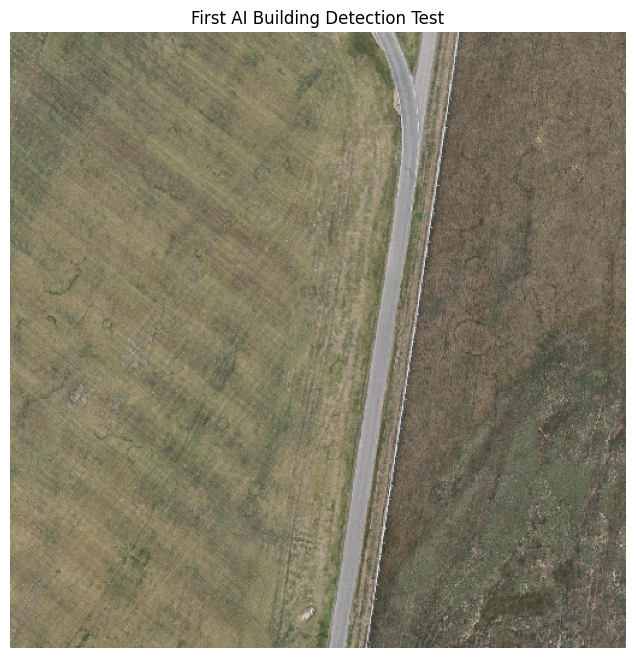

Buildings detected: 0


In [12]:

from huggingface_hub import list_repo_files, hf_hub_download
from PIL import Image
import matplotlib.pyplot as plt

repo = "giswqs/WHU-Building-Dataset"

files = list_repo_files(repo, repo_type="dataset")
images = [
    f for f in files
    if "/Image/" in f and f.lower().endswith((".png", ".jpg"))
]

print("Images found:", len(images))
assert images, "No individual image files found."

image_path = hf_hub_download(
    repo_id=repo,
    repo_type="dataset",
    filename=images[0]
)

image = Image.open(image_path).convert("RGB")

results = building_model.predict(
    source=image,
    conf=0.25,
    imgsz=640,
    verbose=False
)

plt.figure(figsize=(10, 8))
plt.imshow(results[0].plot()[:, :, ::-1])
plt.title("First AI Building Detection Test")
plt.axis("off")
plt.show()

print("Buildings detected:", len(results[0].boxes))


In [13]:

from huggingface_hub import list_repo_files

repo = "giswqs/WHU-Building-Dataset"

# Inspect the actual dataset structure
repo_files = list_repo_files(repo, repo_type="dataset")

print("Total repository files:", len(repo_files))

print("\nFirst 25 files:")
for f in repo_files[:25]:
    print(f)

print("\nPossible annotation files:")
candidates = [
    f for f in repo_files
    if any(word in f.lower() for word in
           ["label", "mask", "annotation", "groundtruth"])
]

for f in candidates[:20]:
    print(f)

print("\nTotal annotation candidates:", len(candidates))



Total repository files: 16378

First 25 files:
.gitattributes
README.md
test/Image/test_0001.png
test/Image/test_0002.png
test/Image/test_0003.png
test/Image/test_0004.png
test/Image/test_0005.png
test/Image/test_0006.png
test/Image/test_0007.png
test/Image/test_0008.png
test/Image/test_0009.png
test/Image/test_0010.png
test/Image/test_0011.png
test/Image/test_0012.png
test/Image/test_0013.png
test/Image/test_0014.png
test/Image/test_0015.png
test/Image/test_0016.png
test/Image/test_0017.png
test/Image/test_0018.png
test/Image/test_0019.png
test/Image/test_0020.png
test/Image/test_0021.png
test/Image/test_0022.png
test/Image/test_0023.png

Possible annotation files:
test/Mask/test_0001.png
test/Mask/test_0002.png
test/Mask/test_0003.png
test/Mask/test_0004.png
test/Mask/test_0005.png
test/Mask/test_0006.png
test/Mask/test_0007.png
test/Mask/test_0008.png
test/Mask/test_0009.png
test/Mask/test_0010.png
test/Mask/test_0011.png
test/Mask/test_0012.png
test/Mask/test_0013.png
test/Mask/tes

test/Mask/test_0001.png: reconstructing file:   0%|          |  0.00B / 1.10kB            

test/Mask/test_0001.png: downloading bytes:           |  0.00B            

test/Mask/test_0002.png: reconstructing file:   0%|          |  0.00B / 8.02kB            

test/Mask/test_0002.png: downloading bytes:           |  0.00B            

Selected test_0002.png: 36.7% building coverage


test/Image/test_0002.png: reconstructing file:   0%|          |  0.00B /  636kB            

test/Image/test_0002.png: downloading bytes:           |  0.00B            

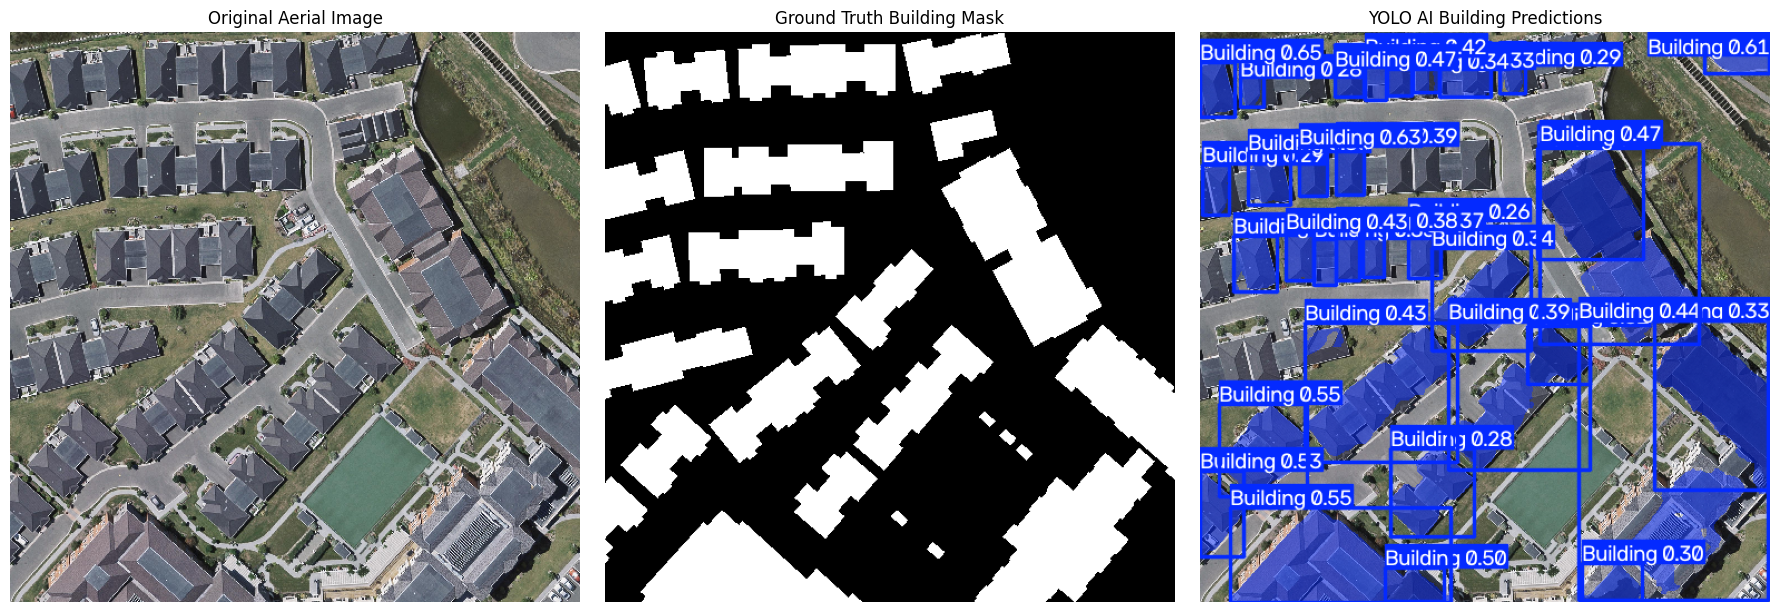

Buildings detected: 33


In [14]:

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from huggingface_hub import hf_hub_download

repo = "giswqs/WHU-Building-Dataset"

selected_image = None
selected_mask = None

# Find an image with a meaningful amount of building coverage
for i in range(1, 31):
    filename = f"test_{i:04d}.png"

    mask_path = hf_hub_download(
        repo_id=repo,
        repo_type="dataset",
        filename=f"test/Mask/{filename}"
    )

    mask = np.array(Image.open(mask_path))
    building_pixels = np.count_nonzero(mask > 0)
    coverage = building_pixels / mask.size

    if coverage > 0.05:
        selected_image = filename
        selected_mask = mask
        print(f"Selected {filename}: {coverage:.1%} building coverage")
        break

if selected_image is None:
    print("No image with >5% building coverage in first 30 samples.")
else:
    image_path = hf_hub_download(
        repo_id=repo,
        repo_type="dataset",
        filename=f"test/Image/{selected_image}"
    )

    image = Image.open(image_path).convert("RGB")

    # Actual AI inference
    results = building_model.predict(
        source=image,
        conf=0.25,
        imgsz=640,
        verbose=False
    )

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    axes[0].imshow(image)
    axes[0].set_title("Original Aerial Image")

    axes[1].imshow(selected_mask, cmap="gray")
    axes[1].set_title("Ground Truth Building Mask")

    axes[2].imshow(results[0].plot()[:, :, ::-1])
    axes[2].set_title("YOLO AI Building Predictions")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

    print("Buildings detected:", len(results[0].boxes))



In [15]:
results[0].save(filename="building_detection_test.png")
print("Detection image saved successfully.")

Detection image saved successfully.


In [16]:
from google.colab import files
files.download("building_detection_test.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
checks = {
    "Earth Engine": "ee" in globals(),
    "YOLO building model": "building_model" in globals(),
    "Interactive map": "Map" in globals(),
    "AI predictions": "results" in globals(),
}

for name, ready in checks.items():
    print(f"{name}: {'READY' if ready else 'NOT FOUND'}")


Earth Engine: READY
YOLO building model: READY
Interactive map: NOT FOUND
AI predictions: READY


In [18]:
import geemap

print("Searching for interactive maps...\n")

found = False

for name, obj in list(globals().items()):
    if isinstance(obj, geemap.Map):
        print(f"FOUND MAP: {name}")
        print(f"Map center: {obj.center}")
        print(f"Zoom level: {obj.zoom}")
        found = True

if not found:
    print("No active geemap map found.")

Searching for interactive maps...

FOUND MAP: m
Map center: [45.315, -75.91]
Zoom level: 12.0


In [19]:
print("Checking existing map selection components...\n")

names = [
    "selected_bounds",
    "selected_area",
    "selected_geometry",
    "draw_control",
    "selection",
    "roi",
    "aoi",
    "m"
]

for name in names:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: FOUND ({type(obj).__name__})")
    else:
        print(f"{name}: not found")

print("\nMap drawing features:")
print("draw_control:", hasattr(m, "draw_control"))
print("draw_last_feature:", hasattr(m, "draw_last_feature"))
print("draw_features:", hasattr(m, "draw_features"))

Checking existing map selection components...

selected_bounds: not found
selected_area: not found
selected_geometry: not found
draw_control: not found
selection: not found
roi: not found
aoi: not found
m: FOUND (Map)

Map drawing features:
draw_control: True
draw_last_feature: True
draw_features: True


In [20]:

import ee

# Retrieve the most recently drawn feature
feature = m.draw_last_feature

if feature is None:
    print("No area selected. Draw a rectangle on the map first.")
else:
    # Convert the drawn feature into Earth Engine geometry
    selected_roi = ee.Feature(feature).geometry()

    # Extract geographic coordinates
    selected_coordinates = selected_roi.bounds().coordinates().getInfo()

    print("Selected area retrieved successfully!")
    print("Bounding coordinates:")
    print(selected_coordinates)

    # Display approximate area
    area_km2 = selected_roi.area(maxError=1).divide(1e6).getInfo()
    print(f"Selected area: {area_km2:.4f} km²")


No area selected. Draw a rectangle on the map first.


In [33]:
display(m)

Map(bottom=752191.0, center=[45.3004900833267, -75.94985961914064], controls=(WidgetControl(options=['position…

In [34]:
print("Drawn features:", len(m.draw_features))
print("Last drawn feature:", m.draw_last_feature)

Drawn features: 1
Last drawn feature: ee.Feature({
  "functionInvocationValue": {
    "functionName": "Feature",
    "arguments": {
      "geometry": {
        "functionInvocationValue": {
          "functionName": "GeometryConstructors.LineString",
          "arguments": {
            "coordinates": {
              "constantValue": [
                [
                  -75.977583,
                  45.297502
                ],
                [
                  -75.984664,
                  45.293396
                ],
                [
                  -75.979214,
                  45.289018
                ],
                [
                  -75.971661,
                  45.293094
                ],
                [
                  -75.97827,
                  45.29726
                ]
              ]
            },
            "geodesic": {
              "constantValue": false
            }
          }
        }
      }
    }
  }
})


In [35]:
import ee

# Retrieve the selected feature
drawn_feature = m.draw_last_feature

# Convert the drawn geometry into a rectangular region
selected_roi = ee.Feature(drawn_feature).geometry().bounds()

# Get the rectangle's coordinates
bounds = selected_roi.coordinates().getInfo()[0]

west = min(point[0] for point in bounds)
east = max(point[0] for point in bounds)
south = min(point[1] for point in bounds)
north = max(point[1] for point in bounds)

# Create a proper rectangular region
selected_roi = ee.Geometry.Rectangle(
    [west, south, east, north]
)

area_km2 = selected_roi.area(maxError=1).divide(1e6).getInfo()

print("Selected area successfully extracted!")
print(f"West: {west:.6f}")
print(f"East: {east:.6f}")
print(f"South: {south:.6f}")
print(f"North: {north:.6f}")
print(f"Area: {area_km2:.4f} km²")

Selected area successfully extracted!
West: -75.984664
East: -75.971661
South: 45.289018
North: 45.297502
Area: 0.9595 km²


In [36]:
import requests

imagery_service = (
    "https://ws.geoservices.lrc.gov.on.ca/arcgis5/rest/services/"
    "AerialImagery/GEO_Imagery_Data_Service_2023to2027/ImageServer"
)

response = requests.get(
    imagery_service,
    params={"f": "json"},
    timeout=30
)

response.raise_for_status()
info = response.json()

if "error" in info:
    raise RuntimeError(info["error"])

print("Service:", info.get("name", "Ontario aerial imagery"))
print("Pixel size:", info.get("pixelSizeX"), info.get("pixelSizeY"))
print("Spatial reference:", info.get("spatialReference"))
print("Export supported:", "exportImage" in info.get("capabilities", ""))

Service: AerialImagery/GEO_Imagery_Data_Service_2023to2027
Pixel size: 0.16000000000000003 0.15999999999999995
Spatial reference: {'wkid': 102100, 'latestWkid': 3857}
Export supported: False


Ottawa aerial image downloaded successfully!
Image dimensions: (512, 512)
Approximate pixel size: 0.2 metres


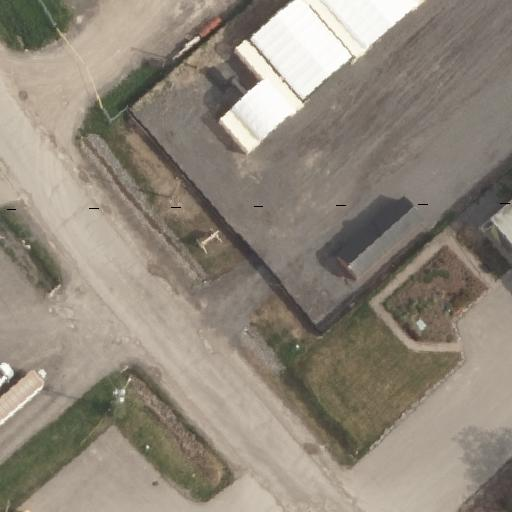

In [37]:

import requests
from PIL import Image
from io import BytesIO
from IPython.display import display

# Centre of the selected Kanata area
center_lon = (west + east) / 2
center_lat = (south + north) / 2

# Convert geographic coordinates to Web Mercator
from pyproj import Transformer

transformer = Transformer.from_crs(
    "EPSG:4326", "EPSG:3857", always_xy=True
)

cx, cy = transformer.transform(center_lon, center_lat)

# Request a small image at 0.20 metres per pixel
pixel_size = 0.20
image_size = 512
half_width = pixel_size * image_size / 2

bbox = [
    cx - half_width,
    cy - half_width,
    cx + half_width,
    cy + half_width
]

export_url = imagery_service.rstrip("/") + "/exportImage"

params = {
    "f": "image",
    "bbox": ",".join(map(str, bbox)),
    "bboxSR": 3857,
    "imageSR": 3857,
    "size": "512,512",
    "format": "jpg",
    "pixelType": "U8",
    "interpolation": "RSP_Bilinear",
}

response = requests.get(
    export_url,
    params=params,
    timeout=90
)

response.raise_for_status()

content_type = response.headers.get("Content-Type", "")

if not content_type.startswith("image/"):
    print("Server response:")
    print(response.text[:1000])
    raise RuntimeError("Image export was not successful.")

ottawa_image = Image.open(
    BytesIO(response.content)
).convert("RGB")

ottawa_image.save("ottawa_aerial_test.jpg")

print("Ottawa aerial image downloaded successfully!")
print("Image dimensions:", ottawa_image.size)
print("Approximate pixel size:", pixel_size, "metres")

display(ottawa_image)


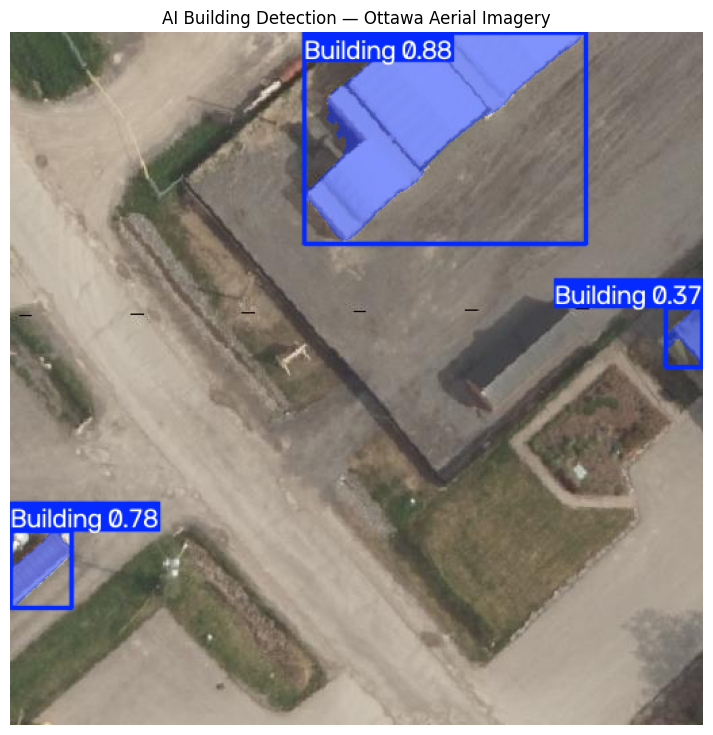

Buildings detected: 3


In [38]:

import matplotlib.pyplot as plt

ottawa_results = building_model.predict(
    source=ottawa_image,
    conf=0.25,
    imgsz=640,
    verbose=False
)

plt.figure(figsize=(9, 9))
plt.imshow(ottawa_results[0].plot()[:, :, ::-1])
plt.title("AI Building Detection — Ottawa Aerial Imagery")
plt.axis("off")
plt.show()

print("Buildings detected:", len(ottawa_results[0].boxes))


In [39]:

drawn_feature = m.draw_last_feature

if drawn_feature is None:
    print("Draw a residential area first.")
else:
    selected_roi = ee.Feature(drawn_feature).geometry().bounds()
    coordinates = selected_roi.coordinates().getInfo()[0]

    west = min(p[0] for p in coordinates)
    east = max(p[0] for p in coordinates)
    south = min(p[1] for p in coordinates)
    north = max(p[1] for p in coordinates)

    print("Residential selection:")
    print("West:", west)
    print("East:", east)
    print("South:", south)
    print("North:", north)


Residential selection:
West: -75.984664
East: -75.971661
South: 45.289018
North: 45.297502


In [40]:
m.add_basemap("Esri.WorldImagery")
display(m)

Map(bottom=188143.0, center=[45.35407536661815, -75.89012145996095], controls=(WidgetControl(options=['positio…

In [41]:
print("Current map layers:")
for layer in m.layers:
    print(layer.name)

Current map layers:
Esri.WorldImagery
Sentinel-2 RGB 2025
NDVI 2025
AAFC forest classes
Study area
Esri.WorldImagery


In [42]:
# Hide analysis layers temporarily
layers_to_hide = [
    "Sentinel-2 RGB 2025",
    "NDVI 2025",
    "AAFC forest classes",
    "Study area"
]

for layer in m.layers:
    if layer.name in layers_to_hide:
        layer.visible = False

# Keep the newest Esri imagery basemap visible
for layer in m.layers:
    if layer.name == "Esri.WorldImagery":
        layer.visible = True

display(m)

Map(bottom=1504020.0, center=[45.30574223273092, -75.92059135437013], controls=(WidgetControl(options=['positi…

In [43]:
# Clear previously drawn shapes without removing map layers
m.draw_control.clear()

print("Previous drawings cleared.")
print("Remaining drawn features:", len(m.draw_features))

Previous drawings cleared.
Remaining drawn features: 0


In [44]:
display(m)

Map(bottom=3007800.0, center=[45.30468580498992, -75.91694355010988], controls=(WidgetControl(options=['positi…

In [45]:
import ee

feature = m.draw_last_feature

if feature is None:
    print("No area selected. Draw a rectangle first.")
else:
    selected_roi = ee.Feature(feature).geometry().bounds()
    coordinates = selected_roi.coordinates().getInfo()[0]

    west = min(p[0] for p in coordinates)
    east = max(p[0] for p in coordinates)
    south = min(p[1] for p in coordinates)
    north = max(p[1] for p in coordinates)

    area_km2 = selected_roi.area(maxError=1).divide(1e6).getInfo()

    print("Residential selection captured!")
    print(f"West: {west:.6f}")
    print(f"East: {east:.6f}")
    print(f"South: {south:.6f}")
    print(f"North: {north:.6f}")
    print(f"Area: {area_km2:.4f} km²")

Residential selection captured!
West: -75.926374
East: -75.923456
South: 45.311929
North: 45.314185
Area: 0.0572 km²


Processing 3 rows x 3 columns
Total tiles: 9
Tile 1,1: 9 predictions
Tile 1,2: 8 predictions
Tile 1,3: 0 predictions
Tile 2,1: 7 predictions
Tile 2,2: 9 predictions
Tile 2,3: 0 predictions
Tile 3,1: 0 predictions
Tile 3,2: 0 predictions
Tile 3,3: 0 predictions

Total raw detections: 33


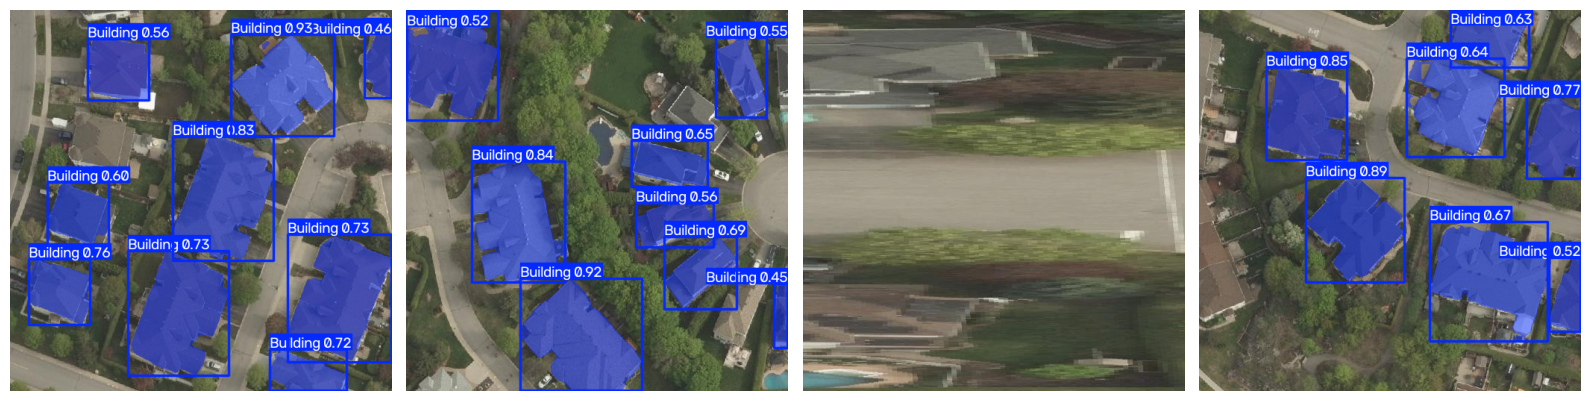

In [46]:

import math
import requests
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from io import BytesIO
from pyproj import Transformer

# Use your latest residential selection
west, east = -75.926374, -75.923456
south, north = 45.311929, 45.314185

# Convert geographic coordinates to Web Mercator
to_mercator = Transformer.from_crs(
    "EPSG:4326", "EPSG:3857", always_xy=True
)

xmin, ymin = to_mercator.transform(west, south)
xmax, ymax = to_mercator.transform(east, north)

tile_size = 512
resolution = 0.30
tile_span = tile_size * resolution

cols = math.ceil((xmax - xmin) / tile_span)
rows = math.ceil((ymax - ymin) / tile_span)

print(f"Processing {rows} rows x {cols} columns")
print(f"Total tiles: {rows * cols}")

# Limit initial test to avoid excessive requests
assert rows * cols <= 16, "Selection too large for initial test"

tile_results = []
detections = []

for row in range(rows):
    for col in range(cols):
        x0 = xmin + col * tile_span
        x1 = min(x0 + tile_span, xmax)

        y1 = ymax - row * tile_span
        y0 = max(y1 - tile_span, ymin)

        params = {
            "f": "image",
            "bbox": f"{x0},{y0},{x1},{y1}",
            "bboxSR": 3857,
            "imageSR": 3857,
            "size": f"{tile_size},{tile_size}",
            "format": "jpg",
            "adjustAspectRatio": "false"
        }

        response = requests.get(
            imagery_service.rstrip("/") + "/exportImage",
            params=params,
            timeout=90
        )
        response.raise_for_status()

        if not response.headers.get(
            "Content-Type", ""
        ).startswith("image/"):
            raise RuntimeError(response.text[:500])

        img = Image.open(
            BytesIO(response.content)
        ).convert("RGB")

        prediction = building_model.predict(
            source=img,
            conf=0.45,
            imgsz=640,
            verbose=False
        )[0]

        tile_results.append((img, prediction))

        for box in prediction.boxes.xyxy.cpu().numpy():
            px0, py0, px1, py1 = box

            # Convert image pixels into geographic
            # coordinates in EPSG:3857
            gx0 = x0 + (px0 / tile_size) * (x1 - x0)
            gx1 = x0 + (px1 / tile_size) * (x1 - x0)
            gy1 = y1 - (py0 / tile_size) * (y1 - y0)
            gy0 = y1 - (py1 / tile_size) * (y1 - y0)

            detections.append(
                (gx0, gy0, gx1, gy1)
            )

        print(
            f"Tile {row + 1},{col + 1}: "
            f"{len(prediction.boxes)} predictions"
        )

print("\nTotal raw detections:", len(detections))

# Preview first four tiles
fig, axes = plt.subplots(
    1, min(4, len(tile_results)),
    figsize=(16, 5),
    squeeze=False
)

for ax, (img, pred) in zip(axes[0], tile_results[:4]):
    ax.imshow(pred.plot()[:, :, ::-1])
    ax.axis("off")

plt.tight_layout()
plt.show()


In [47]:

import ee
from IPython.display import display

# Convert predicted boxes from EPSG:3857 to longitude/latitude
to_lonlat = Transformer.from_crs(
    "EPSG:3857", "EPSG:4326", always_xy=True
)

features = []

for i, (gx0, gy0, gx1, gy1) in enumerate(detections):
    lon0, lat0 = to_lonlat.transform(gx0, gy0)
    lon1, lat1 = to_lonlat.transform(gx1, gy1)

    geometry = ee.Geometry.Rectangle(
        [lon0, lat0, lon1, lat1],
        proj="EPSG:4326",
        geodesic=False
    )

    features.append(
        ee.Feature(geometry, {"detection_id": i + 1})
    )

building_detections_fc = ee.FeatureCollection(features)

# Remove previous AI overlay if rerunning this cell
for layer in list(m.layers):
    if layer.name == "AI Building Detections":
        m.remove_layer(layer)

# Add model predictions as red outlines
styled_detections = building_detections_fc.style(
    color="FF3030",
    fillColor="FF303020",
    width=2
)

m.addLayer(
    styled_detections,
    {},
    "AI Building Detections"
)

# Zoom to the residential selection
m.centerObject(
    ee.Geometry.Rectangle([west, south, east, north]),
    17
)

print("AI detections added to the interactive map!")
print("Raw detection boxes:", len(features))

display(m)


AI detections added to the interactive map!
Raw detection boxes: 33


Map(bottom=12029223.0, center=[45.313057001731764, -75.92491499995664], controls=(WidgetControl(options=['posi…